# Brusselator–ROP

[← All examples](../paper_examples.ipynb)

Exact events and stochastic simulation, compared with approximate oscillatory dynamics. An additional example beyond the paper.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=8d5f826f" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=e158de83" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=50fdaba0" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f0eafb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <span aria-disabled="true" title="Unresolved" style="color:#737d83;display:inline-block;vertical-align:top">ODE<small style="display:block;font-size:10px;font-weight:400">Unresolved</small></span> &amp; <a href="#cell-id=ea26df61" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">pJC</a></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=f08e62e1" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=a3aa08f7" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics<small style="display:block;font-size:10px;font-weight:400">SSA &amp; approximation</small></a></span></nav>

In [1]:
from pathlib import Path
import sys
PACKAGE = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/mfobs').is_dir()))
NOTEBOOKS = PACKAGE / 'notebooks'
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / 'src'), str(PACKAGE)]
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
from IPython.display import display
import paper_view as view
import visual_view as visual
import visual_suite as suite


<h2 id="rules" style="background:#e7f3e9;padding:12px 16px;border-radius:5px">1 · Rules & state space</h2>

Six rules implement the Brusselator reactions, monomer input and X-catalysed lactone growth.


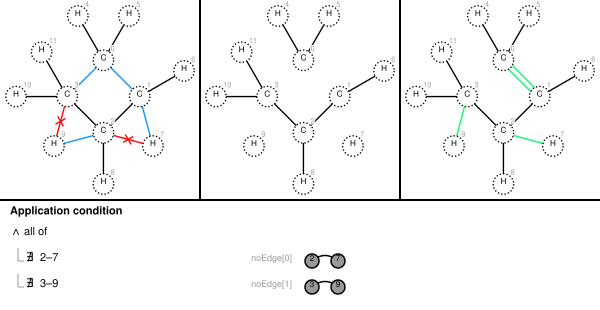

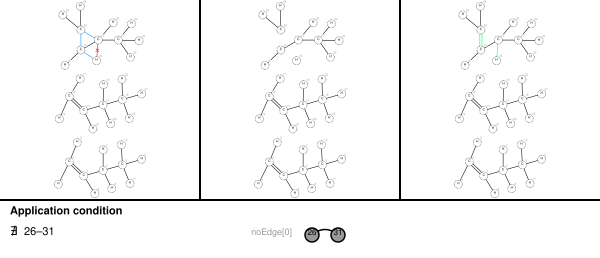

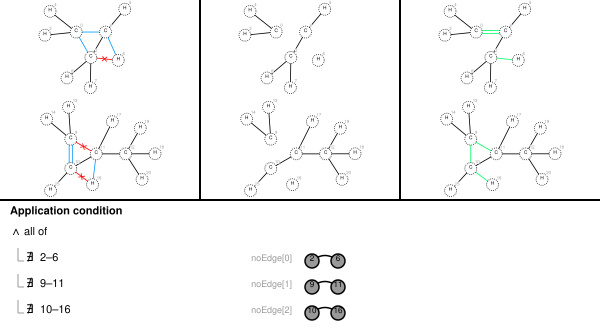

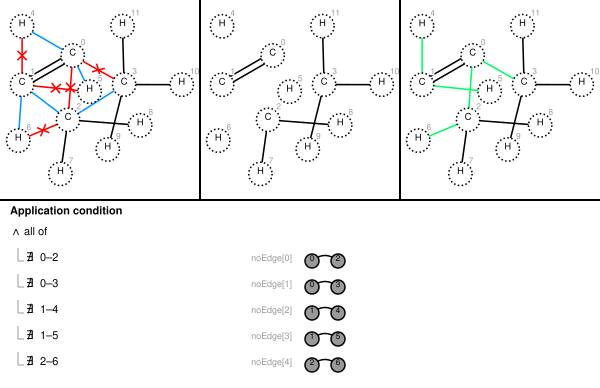

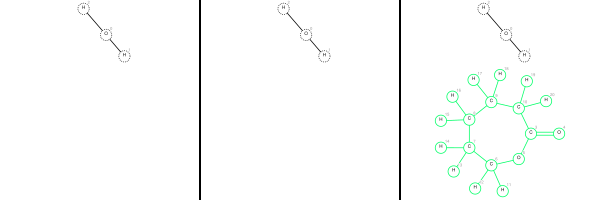

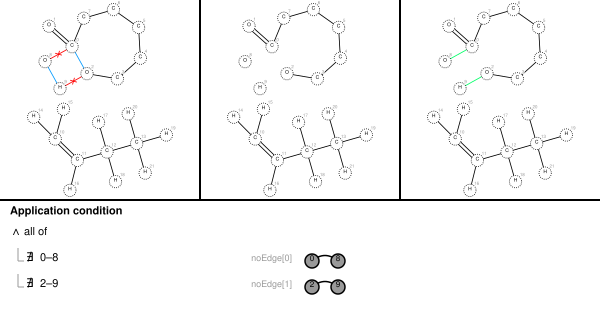

In [2]:
from mfobs.applications import BrusselatorROP
backend = BrusselatorROP()
defaults = backend.specification()
Omega = defaults.omega
rules = defaults.rules
observables = defaults.observables
from mfobs import ModelInputs
inputs = ModelInputs(Omega, rules, observables)
visual.rules(list(inputs.rule_gmls().items()))

<h2 id="inputs" style="background:#fbe9e9;padding:12px 16px;border-radius:5px">2 · Inputs & semantics</h2>

Start with population counts X and Y; discovery adds monomer and chain-length counts.


Molecule counts divide pattern matches by molecular automorphisms.

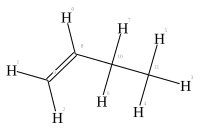

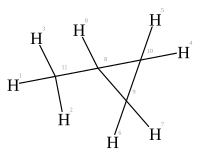

In [3]:
visual.rules(list(inputs.query_gmls().items()), identity=True)

<h2 id="observables" style="background:#e8f0fb;padding:12px 16px;border-radius:5px">3 · Observable discovery</h2>

Run linear closure and event construction independently from the rules.


**Algorithm 1 · Linear expectation closure**

In [4]:
linear = backend.linear_closure(inputs, maximum_dimension=24)
print("Linear expectation closure:", linear["status"])

Linear expectation closure: UNKNOWN_DIMENSION_LIMIT


**Polynomial events**

In [5]:
result = backend.jump_closure(inputs)

In [6]:
result["linear"] = linear
display(view.overview(result))

,Linear closure,Event model,Coordinates,Event rows
0,UNKNOWN_DIMENSION_LIMIT,CLOSED,4,6


<h2 id="ode" style="background:#f0eafb;padding:12px 16px;border-radius:5px">4 · pJC</h2>

The event model is exact. First-moment equations require higher moments; the deterministic approximation factorizes them.


In [7]:
view.show_equations(result)
display(view.show_events(result))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

,Δ X,Δ Y,Δ M,Δ N,Rate
Event,,,,,
source,1,0,0,0,k1*a*V × (1)
autocatalysis,1,-1,0,0,k2/V^2 × (X**2*Y - X*Y)
conversion,-1,1,0,0,k3*b × (X)
sink,-1,0,0,0,k4 × (X)
monomer-inlet,0,0,1,0,beta × (1)
growth,0,0,-1,1,k_g × (M*X)


<h2 id="initial" style="background:#e3f3f0;padding:12px 16px;border-radius:5px">5 · Initial states</h2>

Initial concentrations x,y and counts M,N. X=Vx and Y=Vy for SSA; volume V is in the dynamics settings.

In [8]:
INITIAL = [.4, 2.5, 4., 0.]
visual.table([dict(zip(("x","y","M","N"),INITIAL))])

,x,y,M,N
0,0.4,2.5,4.0,0.0


<h2 id="dynamics" style="background:#fff0de;padding:12px 16px;border-radius:5px">6 · Dynamics</h2>

Compare b=1.8 (damped) and b=2.2 (oscillatory) using the rate control. SSA uses the computed falling-factorial event activity. The band is uncertainty of the sampled mean, not a certified expectation curve.

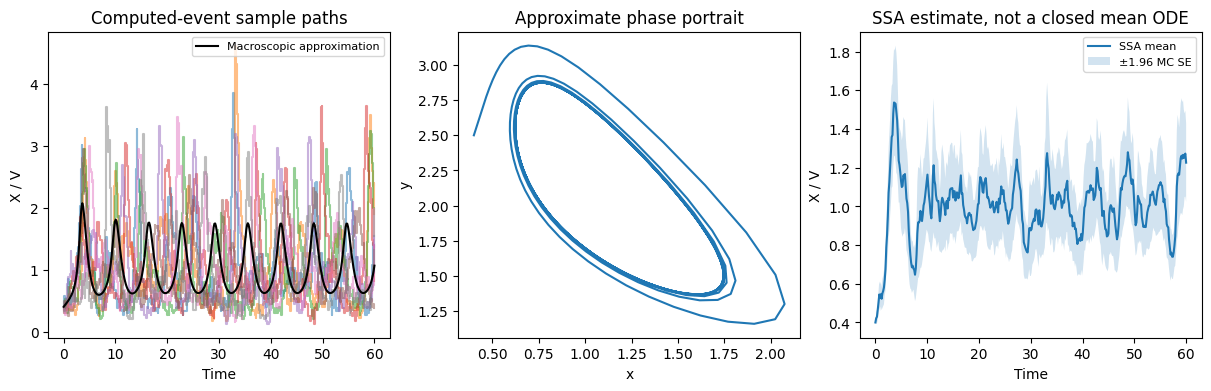

VBox(children=(FloatSlider(value=1.0, continuous_update=False, description='a', max=3.0, step=0.05), FloatSlid…

In [9]:
T = 60.0
RUNS = 32
SEED = 20260924
VOLUME = 40
rates = dict(a=1.0, b=2.2, k1=1.0, k2=1.0, k3=1.0, k4=1.0, beta=0.3, k_g=0.15)
curves = suite.bruss_curve(result, INITIAL, rates, end=T, paths=RUNS, seed=SEED, volume=VOLUME)
controls = suite.rate_controls(
    lambda rates, **opts: suite.bruss_curve(result, INITIAL, rates, **opts), rates, curves['options'])

[← All examples](../paper_examples.ipynb)